In [78]:
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
import math
import pandas as pd
import os.path, os, sys, glob, json, pathlib
import jinja2
from multiprocessing import Pool

plt.style.use('dark_background')
plt.rcParams.update({'font.size': 18, 'figure.figsize': [10.0, 8]})

def generate_from_template(templatefile, outfile, **kwargs):
    with open(templatefile, 'r') as infile, open(outfile, 'w') as outfile:
        output = jinja2.Template(infile.read()).render(kwargs)
        outfile.write(output)

try:
    workdir
except NameError:
    workdir=%pwd
else:
    %cd -q $workdir
%cd -q $workdir/

faunus_dir = '$HOME/github/faunus/' # change this!!
faunus_exe = faunus_dir+'/cmake-build-release-gcc11/faunus'
faunus_yason = faunus_dir+'/scripts/yason.py'

#assert os.path.isfile(faunus_yason)# and os.access(faunus_yason, os.X_OK)

## Generate Faunus input file from a _template_

In the following snippet, we start from a template input file, `template.yml` and generate a final input file for Faunus. The idea is that the template contains named variables that we can fill in and save an input file.

In [103]:
%cd -q $workdir
template_file = 'template.yml'
generate_from_template('template.yml', 'isotropic/input.yml', micro_steps=10000, structure='../P00.xyz')
generate_from_template('template.yml', 'dipolar/input.yml', micro_steps=10000, structure='../P18.xyz')

## Run Monte Carlo simulation

We now parse the input to the _faunus_ executable which we assume you have compiled elsewhere.

In [50]:
%cd -q $workdir/dipolar
!{faunus_yason} input.yml | {faunus_exe} --verbosity 5 -s state.json

[faunus 4301] I: Reading molecule configuration from file: ../P18.xyz
[faunus 4301] D: comment line:  generated by VMD
[faunus 4301] I: adding 10 macroion molecules --> 1.48659E-02 mol/l (0 inactive)
[faunus 4301] I: adding 180 cation molecules --> 2.67587E-01 mol/l (0 inactive)
[faunus 4301] I: adding 100 anion molecules --> 1.48659E-01 mol/l (0 inactive)
[faunus 4301] I: splitting function for 'plain' splined with 2 knots
[faunus 4301] D: Combination rule lorentz_berthelot in effect for the wca potential.
[faunus 4301] D: Adding self-energy from coulomb/wca to hamiltonian
[faunus 4301] D: activated instant energy summation
[faunus 4301] D: setting summation policy to "serial"
[faunus 4301] D: hamiltonian expanded with nonbonded_coulombwca
[faunus 4301] D: repeat = 10 for molecule 'macroion'
[faunus 4301] I: initial energy = 2.646028E+09 kT
[faunus 4301] I: loading state file state.json
[faunus 4301] I: initial energy = -2.670548E+02 kT
[===============================================

## Extract information from main output file: `out.json`

We simply read the JSON file as a dictionary. Try to use `print(j)` to see the full structure.

In [3]:
def searchOutput(json_output, section, name):
    ''' helper function to search through lists in the output '''
    for item in json_output[section]:
        if (name in item):
            return item[name]
    assert(false)

%cd -q $workdir/dipolar
with open('out.json') as f:
    j = json.load(f) # load entire json file as a dict
    systemenergy = searchOutput(j, 'analysis', 'systemenergy')
    print('mean energy = {:.4} kT'.format(systemenergy['mean']))
    
    transrot = searchOutput(j, 'moves', 'transrot')
    mean_square_displacement = transrot['√⟨r²⟩']
    translate_acceptance = transrot['acceptance']

    print('mean square displacement = {} Å'.format(mean_square_displacement))
    print('acceptance = {}%'.format(translate_acceptance * 100))
    
    density = searchOutput(j, 'analysis', 'atom_density')
    na_conc = density['densities']['Na']['c/M']
    cl_conc = density['densities']['Cl']['c/M']
    print('Na+ concentration (M) = ', na_conc)
    print('Cl- concentration (M) = ', cl_conc)
    print('ionic strength (M) = ', 0.5*(na_conc+cl_conc))

mean energy = -252.7 kT
mean square displacement = 7.77 Å
acceptance = 58.3%
Na+ concentration (M) =  0.1626
Cl- concentration (M) =  0.04364
ionic strength (M) =  0.10311999999999999


In [99]:
def excessPressure(j):
    ''' excess pressure in mM '''
    return searchOutput(j, 'analysis', 'virtualvolume')['Pex/mM']
 
def idealPressure(j):
    ''' ideal pressure in mM (salt and protein) '''
    cations = searchOutput(j, 'analysis', 'atom_density')['densities']['Na']['c/M']
    anions = searchOutput(j, 'analysis', 'atom_density')['densities']['Cl']['c/M']
    protein = 0
    number_of_proteins = j["number of groups"] - 2
    if number_of_proteins > 0:
        box_length = j['geometry']['length'][0]
        protein = number_of_proteins / box_length**3 * 1e27 / 6.022e23
    return (cations+anions+protein) * 1000 # --> mM
    
def pressure(outfile):
    with open(outfile) as f:
        j = json.load(f) # load entire json file as a dict
        return dict(ideal=idealPressure(j), excess=excessPressure(j),
                    total=idealPressure(j) + excessPressure(j))

%cd -q $workdir

files = dict(Bulk='bulk/out.json', Neutral='neutral/out.json', Isotropic='isotropic/out.json', Anisotropic='dipolar/out.json')
d = pd.DataFrame({name:pressure(file) for (name, file) in files.items()}).T
d = (d - d.iloc[0]).tail(3) # subtract bulk pressure (first row)
pd.set_option("display.precision", 1)
d

,ideal,excess,total
Neutral,-104.4,185.5,81.1
Isotropic,-50.4,193.0,142.6
Anisotropic,-35.9,143.6,107.7


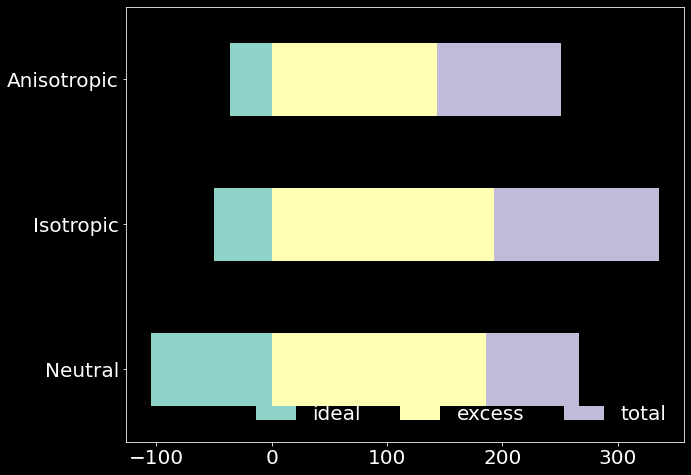

In [142]:
ax = d.plot.barh(stacked=True)
ax.legend(frameon=False, loc=4, ncol=3)


mean energy = 0.0001027 kT


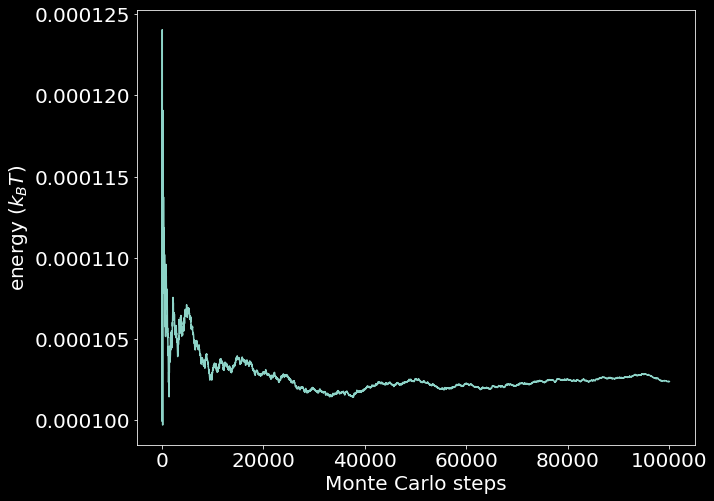

In [104]:
%cd -q $workdir/neutral

steps, nonbonded_energy = np.loadtxt('pressure.dat.gz', usecols=[0,4], unpack=True)
plt.plot(steps, nonbonded_energy)
plt.xlabel('Monte Carlo steps')
plt.ylabel('energy ($k_BT$)')
print('mean energy = {:.4} kT'.format(nonbonded_energy.mean()))

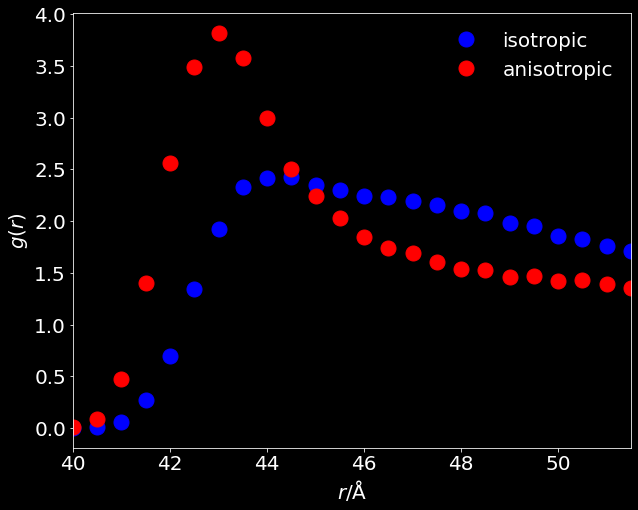

In [119]:
plt.rcParams.update({'font.size': 20, 'figure.figsize': [10.0, 8]})

# %cd -q $workdir/neutral
# r, g = np.loadtxt('rdf.dat', unpack=True)
# plt.plot(r, g, 'g-', label='neutral', ms=15)

%cd -q $workdir/isotropic
r, g = np.loadtxt('rdf.dat', unpack=True)
plt.plot(r, g, 'bo', label='isotropic', ms=15)

%cd -q $workdir/dipolar
r, g = np.loadtxt('rdf.dat', unpack=True)
plt.plot(r, g, 'ro', label='anisotropic', ms=15)

plt.legend(loc=0, frameon=False)
plt.xlim(40, 103/2)
plt.ylabel(r'$g(r)$')
plt.xlabel(r'$r$/Å')
plt.savefig('plot.pdf', bbox_inches='tight')

(0.1, 0.2)

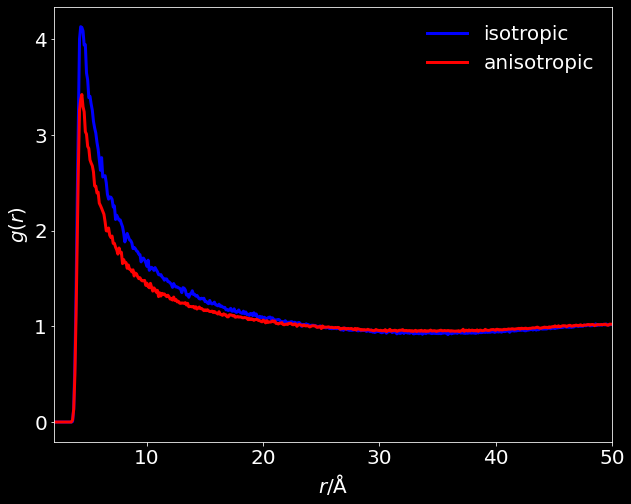

In [127]:
plt.rcParams.update({'font.size': 20, 'figure.figsize': [10.0, 8]})

%cd -q $workdir/isotropic
r1, g1 = np.loadtxt('rdf-nacl.dat', unpack=True)
plt.plot(r1, g1, 'b-', label='isotropic', ms=15, lw=3)

%cd -q $workdir/dipolar
r2, g2 = np.loadtxt('rdf-nacl.dat', unpack=True)
plt.plot(r2, g2, 'r-', label='anisotropic', ms=15, lw=3)

plt.legend(loc=0, frameon=False)
plt.xlim(2, 50)
plt.ylabel(r'$g(r)$')
plt.xlabel(r'$r$/Å')
plt.savefig('plot.pdf', bbox_inches='tight')

r1[0], r2[1]